<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b>. The time windows in this notebook (in &micro;s or ms) were halved so that they still cover the same samples, so the selection of events and every number counted in samples or counts is unchanged; the absorbed energies are half of what the earlier version printed.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

# One pulse in QET current, power and absorbed energy: series 07221203_2025, dump 1

What a pulse sample measures is the current in the QET branch, and the QET current changes because the power in the TES changes. This notebook follows **one real pulse**, from one channel of one of the small real triggers of `small-physics-triggers-07221203_2025.ipynb`, from ADC counts to the energy absorbed in the QETs:

1. **Counts to QET current.** Subtract the baseline (a quadratic fitted before the pulse and in the late tail) and convert with the rules of the note: counts / 6553.6 gives volts, divided by $R_\mathrm{fb}\,G_\mathrm{loop}\,G_\mathrm{DCRC}\,G_\mathrm{driver}$ gives the QET-branch current $\Delta I(t)$.
2. **QET current to power.** $\Delta P(t) = (\mathrm{d}P/\mathrm{d}I)\,\Delta I(t)$ with the wiki's operating-point value $\mathrm{d}P/\mathrm{d}I = 1.0\ \mu\mathrm{V}$ (linear approximation). The pulse is then a **power as a function of time**.
3. **Power to energy.** The absorbed energy is the area under that power, $E_\mathrm{abs} = \int \Delta P\,\mathrm{d}t = (\mathrm{d}P/\mathrm{d}I)\int \Delta I\,\mathrm{d}t$, in joules and keV, channel by channel.
4. **Absorbed to deposited energy.** With the phonon collection efficiency $\mathrm{PCE}$ (the wiki's 0 V value for this detector, about 0.32) the total phonon energy is $E_\mathrm{abs}/\mathrm{PCE}$. For this biased series the Neganov-Luke phonons are included in it; they are not removed here.

**None of the constants has been measured for this series.** They are the wiki's numbers (see the note): the gain of 170 counts per $\mu$A rests on an interpretation of the "loop gain" 10.5, the sample period is 0.8 $\mu$s (1.25 MHz; the notebooks used a wrong 1.6 $\mu$s until 2026-10-22), and $\mathrm{d}P/\mathrm{d}I$ is the Run 75/76 set point, not a December 2022 measurement. The numbers below are therefore the size of the effect, not a calibration.

In [1]:
import sys
import warnings
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))
sys.path.insert(0, str(Path.cwd().resolve()))      # this notebook's folder, for small_triggers.py

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

import small_triggers as st

warnings.filterwarnings("once")
FIGDIR = Path("..") / "figures"      # the figures folder of the R76 notebooks
FIGDIR.mkdir(exist_ok=True)

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


## 1. Load the dump and pick a pulse

The real triggers (label `Unknown`, the labels are swapped) with a quiet pretrigger and a largest rise height between `AMP_LOW` and `AMP_HIGH` counts, as in the other notebooks. `EVENT` and `CHANNEL` choose the pulse; left as `None` the event is the one at the median height of the selection and the channel is the one with the largest rise height in it. The list printed below gives the selected events to choose from.

In [2]:
DUMP = "07221203_2025_F0001"          # series 07221203_2025, dump 1
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]

trigger_types = pio.trigger_types(cdms, det_ids[0])
real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
rand = pc.randoms(trigger_types)
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])

traces, amp, pre_rms, dead = {}, {}, {}, []
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    if np.all(p.std(axis=1) == 0):
        dead.append(key)
        continue
    traces[key] = np.asarray(p, dtype=float)
    amp[key] = st.rise_height(p, config_500)
    pre_rms[key] = st.pretrigger_residual_rms(p, config_500)
working = list(traces)
name = lambda key: pch.channel_name(*key)
A = np.array([amp[k] for k in working])
amp_max = A.max(axis=0)
max_channel = [working[i] for i in A.argmax(axis=0)]

AMP_LOW, AMP_HIGH = 15.0, 200.0           # counts: the provisional 'small pulses' range
pre_ratio, quiet_pre = st.quiet_pretrigger(pre_rms, rand)
selected = real & quiet_pre & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)
sel = np.flatnonzero(selected)
print(f"{selected.sum()} selected events (real triggers, quiet pretrigger, largest rise height {AMP_LOW:.0f} to {AMP_HIGH:.0f} counts)")
print("event (largest rise height, counts, channel):", ", ".join(f"{event_numbers[i]} ({amp_max[i]:.0f}, {name(max_channel[i])})" for i in sel))

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:8: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:9: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  rand = pc.randoms(trigger_types)


48 selected events (real triggers, quiet pretrigger, largest rise height 15 to 200 counts)
event (largest rise height, counts, channel): 11083 (125, Side2pF), 11095 (32, Side2pF), 11114 (105, Side2pF), 11122 (52, Side2pF), 11148 (83, Side1pB), 11153 (136, Side1pB), 11158 (47, Side1pB), 11162 (101, Side1pB), 11164 (152, Side1pB), 11171 (167, Side1pB), 11188 (35, Side2pF), 11196 (34, Side2pE), 11206 (49, Side2pF), 11215 (19, Side2pF), 11221 (70, Side1pB), 11247 (17, Side2pE), 11253 (27, Side1pB), 11256 (25, Side2pF), 11266 (118, Side2pF), 11291 (30, Side2pE), 11295 (112, Side1pB), 11300 (29, Side2pF), 11303 (40, Side2pF), 11309 (25, Side2pF), 11315 (34, Side2pF), 11318 (184, Side1pB), 11320 (41, Side2pF), 11324 (50, Side2pF), 11343 (55, Side2pF), 11359 (26, Side1pF), 11372 (41, Side2pE), 11375 (38, Side2pE), 11381 (28, Side2pF), 11396 (20, Side2pE), 11409 (25, Side2pF), 11436 (19, Side2pF), 11437 (16, Side2pE), 11439 (18, Side1pB), 11440 (80, Side1pB), 11462 (165, Side1pB), 11467 (104, S

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)
C:\Users\villanoa\Research\NSDF-Data-pn\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel).name


In [3]:
EVENT = None          # an event number from the list above, or None for the median-height selected event
CHANNEL = None        # a channel name such as "Side1pB", or None for the channel with the largest rise height

if EVENT is None:
    i = sel[np.argsort(amp_max[sel])[len(sel) // 2]]
else:
    i = int(np.flatnonzero(event_numbers == EVENT)[0])
key = max_channel[i] if CHANNEL is None else pch.find_channel(CHANNEL)
assert key in working, f"{name(key)} is a dead channel"
print(f"pulse: event {event_numbers[i]}, channel {name(key)} ({pch.channel_info(*key).dcrc}), rise height {amp[key][i]:.1f} counts")

pulse: event 11486, channel Side2pF (DCRC1), rise height 43.1 counts


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1436115252.py:10: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"pulse: event {event_numbers[i]}, channel {name(key)} ({pch.channel_info(*key).dcrc}), rise height {amp[key][i]:.1f} counts")


## 2. The constants

All from the Run 76 calibration code and the Run 75 summary of the UMN wiki, as in the note (sections *Pulses in QET current units* and *dP/dI*). They are not measured for this series.

In [4]:
ADC_PER_V = 6553.6        # counts per volt (65536 / 10 V)
R_FB = 1233.0             # feedback resistor, ohm
G_LOOP = 10.5             # 'loop gain': I_fb = G_LOOP * I_QET (read as the coil ratio M / M_f)
G_DCRC = 2.0              # DCRC gain of the calibration code (which ODB field it is, is not settled)
G_DRIVER = 1.0            # driver gain of the calibration code
DPDI = 1.0e-6             # V: dP/dI at the operating point (Run 75/76 set point)
JOULE_PER_KEV = 1.60218e-16
PCE = 0.32                # phonon collection efficiency of this detector at 0 V (wiki: 0.313 at low energy, 0.331 at 60 keV)
AMP_PER_COUNT = 1.0 / (ADC_PER_V * R_FB * G_LOOP * G_DCRC * G_DRIVER)       # A of QET current per ADC count
print(f"QET current per count: {AMP_PER_COUNT * 1e9:.2f} nA, i.e. {1e-6 / AMP_PER_COUNT:.0f} counts per uA")

QET current per count: 5.89 nA, i.e. 170 counts per uA


## 3. From counts to QET current

The raw trace, the two-sided baseline (a quadratic fitted to the pretrigger samples and to the late tail, with the pulse left out) and the trace with the baseline subtracted, $\Delta N(t)$ in counts. Multiplying by the current per count gives $\Delta I(t)$ (the second axis). The sign is that of the ADC counts (the pulses rise); only the size matters here.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


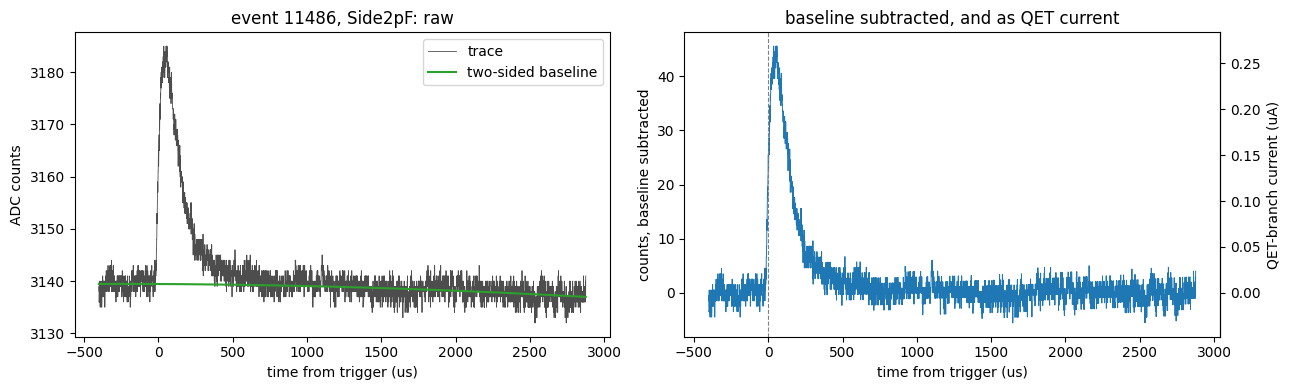

peak: 45.6 counts = 0.268 uA at 59 us after the trigger


In [5]:
dt = config_500.sample_period_s
n_samples = traces[key].shape[1]
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * dt * 1e6
raw = traces[key][i]
baseline = st.two_sided_baseline(raw[None, :], config_500)[0]
dN = raw - baseline                           # counts
dI = dN * AMP_PER_COUNT                       # A, QET-branch current

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(t_us, raw, color="0.3", linewidth=0.6, label="trace")
ax.plot(t_us, baseline, color="C2", label="two-sided baseline")
ax.set_xlabel("time from trigger (us)"); ax.set_ylabel("ADC counts"); ax.legend()
ax.set_title(f"event {event_numbers[i]}, {name(key)}: raw")
ax = axes[1]
ax.plot(t_us, dN, color="C0", linewidth=0.7)
ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
ax.set_xlabel("time from trigger (us)"); ax.set_ylabel("counts, baseline subtracted")
ax2 = ax.secondary_yaxis("right", functions=(lambda n: n * AMP_PER_COUNT * 1e6, lambda u: u / (AMP_PER_COUNT * 1e6)))
ax2.set_ylabel("QET-branch current (uA)")
ax.set_title("baseline subtracted, and as QET current")
fig.tight_layout()
plt.show()
peak = int(np.argmax(dN))
print(f"peak: {dN[peak]:.1f} counts = {dI[peak] * 1e6:.3f} uA at {t_us[peak]:.0f} us after the trigger")

## 4. From current to power, and the absorbed energy

With the linear approximation $\Delta P(t) = (\mathrm{d}P/\mathrm{d}I)\,\Delta I(t)$, the same trace is a power as a function of time (picowatts: $\mu\mathrm{V}\times\mu\mathrm{A} = \mathrm{pW}$). Its running integral is the energy absorbed in the QETs so far, and the integral over the pulse is $E_\mathrm{abs}$. The integration runs from the trigger to `INT_END_US`, before the late tail used for the baseline.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)


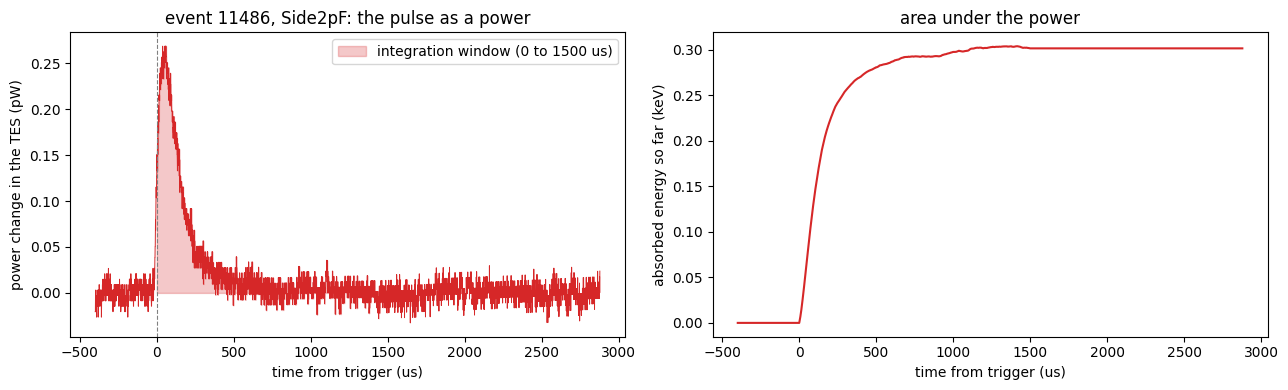

charge through the QET branch in the window: 48.3 pC (uA s x 1e-6)
E_abs = (dP/dI) x charge = 4.830e-17 J = 0.30 keV in this channel (sample period 0.8 us)


In [6]:
INT_START_US, INT_END_US = 0.0, 1500.0
window = (t_us >= INT_START_US) & (t_us < INT_END_US)

dP = DPDI * dI                                # W
cumulative = np.cumsum(np.where(window, dP, 0.0)) * dt        # J
charge = dI[window].sum() * dt                                  # C = A s
E_abs_J = DPDI * charge
E_abs_keV = E_abs_J / JOULE_PER_KEV

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(t_us, dP * 1e12, color="C3", linewidth=0.7)
ax.fill_between(t_us, 0, dP * 1e12, where=window, color="C3", alpha=0.25, label=f"integration window ({INT_START_US:.0f} to {INT_END_US:.0f} us)")
ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
ax.set_xlabel("time from trigger (us)"); ax.set_ylabel("power change in the TES (pW)"); ax.legend()
ax.set_title(f"event {event_numbers[i]}, {name(key)}: the pulse as a power")
ax = axes[1]
ax.plot(t_us, cumulative / JOULE_PER_KEV, color="C3")
ax.set_xlabel("time from trigger (us)"); ax.set_ylabel("absorbed energy so far (keV)")
ax.set_title("area under the power")
fig.tight_layout()
fig.savefig(FIGDIR / f"pulse-as-power-event{event_numbers[i]}-{name(key)}-{DUMP}.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"charge through the QET branch in the window: {charge * 1e12:.1f} pC (uA s x 1e-6)")
print(f"E_abs = (dP/dI) x charge = {E_abs_J:.3e} J = {E_abs_keV:.2f} keV in this channel (sample period {dt * 1e6:.1f} us)")

## 5. All the QET channels of the event

The same conversion for every working channel of the event. `Side2pB` (DCRC4 channel pA) is probably not a QET channel in this series (the NaI trigger input), so it is listed but left out of the sum. `Side1pE` and `Side2pE` have `VGAGain` 5 in the September 2022 ODB against 2 on the others; if that scales their gain, their energies are too large by up to a factor 2.5 here (not applied).

In [7]:
rows = []
for k in working:
    d = traces[k][i] - st.two_sided_baseline(traces[k][i][None, :], config_500)[0]
    di = d * AMP_PER_COUNT
    q = di[window].sum() * dt
    rows.append((name(k), pch.channel_info(*k).dcrc, d.max(), d.max() * AMP_PER_COUNT * 1e6, q * 1e12, DPDI * q / JOULE_PER_KEV, k))
print(f"{'channel':<9}{'board':<7}{'peak (counts)':>14}{'peak (uA)':>11}{'charge (pC)':>13}{'E_abs (keV)':>13}")
for n, b, pk, pk_ua, qpc, e, k in rows:
    print(f"{n:<9}{b:<7}{pk:>14.1f}{pk_ua:>11.3f}{qpc:>13.1f}{e:>13.2f}" + ("   (not a QET channel: left out of the sum)" if n == "Side2pB" else ""))
E_total_keV = sum(r[5] for r in rows if r[0] != "Side2pB")
print(f"\nsum over the QET channels: E_abs = {E_total_keV:.2f} keV")

channel  board   peak (counts)  peak (uA)  charge (pC)  E_abs (keV)
Side2pC  DCRC1            27.5      0.162         31.7         0.20
Side2pF  DCRC1            45.6      0.268         48.3         0.30
Side1pF  DCRC1            20.1      0.119         18.8         0.12
Side1pE  DCRC3            30.8      0.181         36.0         0.22
Side1pB  DCRC3            24.4      0.144         19.7         0.12
Side2pE  DCRC3            34.9      0.206         29.9         0.19
Side2pB  DCRC4             5.8      0.034          1.0         0.01   (not a QET channel: left out of the sum)

sum over the QET channels: E_abs = 1.15 keV


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1319683739.py:22: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  name = lambda key: pch.channel_name(*key)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\3291166651.py:6: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  rows.append((name(k), pch.channel_info(*k).dcrc, d.max(), d.max() * AMP_PER_COUNT * 1e6, q * 1e12, DPDI * q / JOULE_PER_KEV, k))


## 6. From the absorbed energy to the phonon energy

If the QETs collect a fraction $\mathrm{PCE}$ of the phonon energy, the total phonon energy of the event is $E_\mathrm{abs}/\mathrm{PCE}$. The wiki measured the PCE of this detector with americium lines at 0 V in the first Run 76 series (March to April 2022): about 0.32, 0.313 at low energy and 0.331 at 60 keV, "the highest PCE we've ever measured". Not measured for December 2022. This series was taken with the detector at $-83.2$ V, so the phonon energy contains the Neganov-Luke phonons, which add roughly $eV_\mathrm{b}$ per electron-hole pair: for an electron recoil in germanium $E_\mathrm{phonon} = E_\mathrm{r}(1 + eV_\mathrm{b}/\varepsilon)$, with $\varepsilon \approx 3.0$ eV (an assumption). The last line shows what that would mean if this event were an electron recoil; it is an illustration, not an identification of the event.

In [8]:
E_phonon_keV = E_total_keV / PCE
V_BIAS = 83.2             # V, detector bias of the series (diary of 3 December 2022)
EPS_EH = 3.0e-3           # keV, energy per electron-hole pair in germanium (assumed)
LUKE = 1.0 + V_BIAS / (EPS_EH * 1e3)
print(f"E_abs (sum over the QET channels) = {E_total_keV:.2f} keV;  PCE = {PCE:.2f}  ->  total phonon energy = {E_phonon_keV:.2f} keV")
print(f"if an electron recoil at {V_BIAS} V: Neganov-Luke factor 1 + eV/eps = {LUKE:.1f}  ->  recoil energy = {E_phonon_keV / LUKE:.2f} keV")


E_abs (sum over the QET channels) = 1.15 keV;  PCE = 0.32  ->  total phonon energy = 3.59 keV
if an electron recoil at 83.2 V: Neganov-Luke factor 1 + eV/eps = 28.7  ->  recoil energy = 0.13 keV


## 7. Is the linear approximation good for this pulse?

$\Delta P = (\mathrm{d}P/\mathrm{d}I)\,\Delta I$ holds when the change of the current is small compared with the QET current itself (the wiki gives a second-order correction for strong pulses). The QET current at the operating point is about 20 $\mu$A in the Run 75 IbIs curves near the transition (a reading of the plot); the largest peak of this event compared with it:

In [9]:
I_S = 20e-6        # A, QET current near the operating point (read from the Run 75 IbIs plot)
biggest = max(rows, key=lambda r: r[2])
print(f"largest peak of the event: {biggest[0]}, {biggest[3]:.2f} uA = {biggest[3] * 1e-6 / I_S * 100:.1f}% of {I_S * 1e6:.0f} uA")
print("for the largest pulses of the dump (about 1000 counts, 5.9 uA) the ratio would be about 30%: the linear approximation is then rough and the second-order correction matters")

largest peak of the event: Side2pF, 0.27 uA = 1.3% of 20 uA
for the largest pulses of the dump (about 1000 counts, 5.9 uA) the ratio would be about 30%: the linear approximation is then rough and the second-order correction matters
